# 00. Data exploration

Goal: understand the label distributions and input properties **before** choosing prompts and training settings.
All figures are saved to `results/figures/` for the report. `protect-frsemcor` splits are already removed by `load_data()`.

In [1]:
# Setup: on Colab or Kaggle, clone (or update) the repository so that `src/` is importable; locally, run from the repo root.
import os, sys
REPO_URL = "https://github.com/Alhassliebe/LAB1_classification_with_llms.git"
ON_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
if "google.colab" in sys.modules or ON_KAGGLE:
    REPO_DIR = ("/kaggle/working" if ON_KAGGLE else "/content") + "/LAB1_classification_with_llms"
    if not os.path.exists(REPO_DIR):
        !git clone -q {REPO_URL} {REPO_DIR}
    else:
        !git -C {REPO_DIR} pull -q
    os.chdir(REPO_DIR)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

In [2]:
import re
import matplotlib.pyplot as plt
import pandas as pd
from src.data import load_data, SUPERSENSES, HYPERSENSES

SPLITS = ["train", "rand-dev", "rand-test", "freq-dev", "freq-test"]
FIG_DIR = "results/figures"
df = load_data()

## 1. Split sizes

In [3]:
df["set"].value_counts().reindex(SPLITS).to_frame("n_senses")

,n_senses
set,
train,10604
rand-dev,570
rand-test,678
freq-dev,1760
freq-test,1521


## 2. Label distributions per split

Splits have very different sizes, so we compare **proportions** (each column sums to 1) rather than counts.

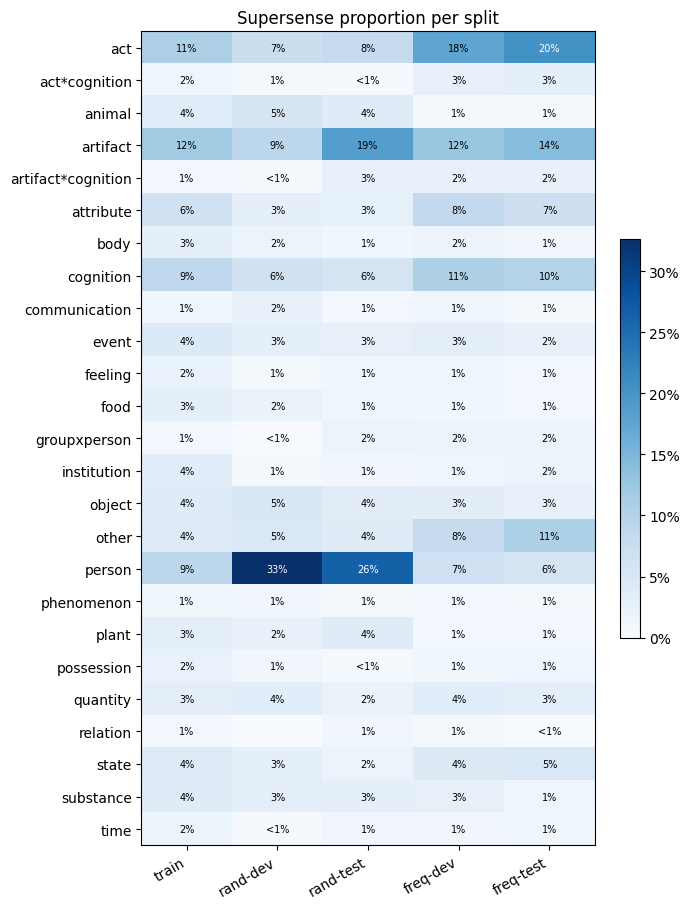

In [4]:
def plot_label_heatmap(labels, col, path):
    """Heatmap of label proportions (rows) per split (columns), saved to `path`."""
    props = pd.crosstab(df[col], df["set"], normalize="columns").reindex(index=labels, columns=SPLITS)
    fig, ax = plt.subplots(figsize=(7, 0.32 * len(labels) + 1.2))
    im = ax.imshow(props, cmap="Blues", aspect="auto", vmin=0)
    ax.set_xticks(range(len(SPLITS)), SPLITS, rotation=30, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    for i, j in [(i, j) for i in range(len(labels)) for j in range(len(SPLITS))]:
        v = props.iat[i, j]
        ax.text(j, i, f"{v:.0%}" if v >= 0.005 else ("<1%" if v > 0 else ""), ha="center", va="center", fontsize=7,
                color="white" if v > 0.6 * props.values.max() else "black")
    fig.colorbar(im, ax=ax, format=lambda x, _: f"{x:.0%}", fraction=0.04)
    ax.set_title(f"{col.capitalize()} proportion per split")
    fig.tight_layout()
    fig.savefig(path, dpi=200)
    plt.show()
    return props

super_props = plot_label_heatmap(SUPERSENSES, "supersense", f"{FIG_DIR}/supersense_by_split.png")

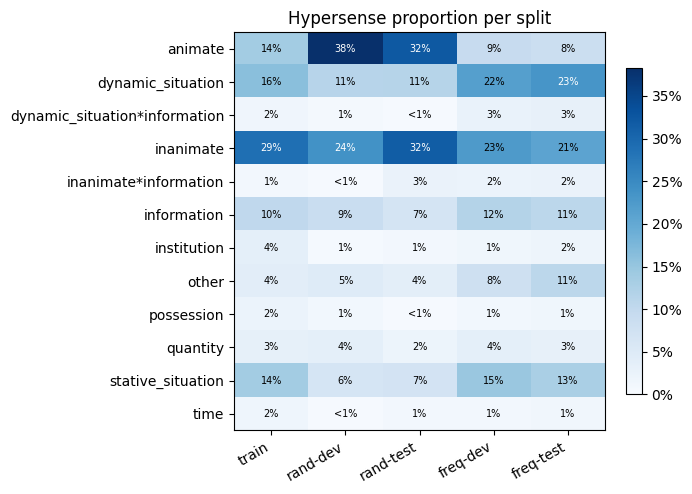

In [5]:
hyper_props = plot_label_heatmap(HYPERSENSES, "hypersense", f"{FIG_DIR}/hypersense_by_split.png")

## 3. Properties of the inputs

In [6]:
# Shallow cues that a classifier (or an LLM) may rely on, besides the meaning of the definition.
df["n_words"] = df["definition"].str.split().str.len()
df["lemma_in_def"] = [l.lower() in d.lower() for l, d in zip(df["lemma"], df["definition"])]
df["starts_synonyme_variante"] = df["definition"].str.match(r"(Synonyme|Variante) de", flags=re.I)
df["in_frsemcor"] = df["nb_occ_lemma_frsemcor"] > 0

input_stats = df.groupby("set")[["n_words", "lemma_in_def", "starts_synonyme_variante", "in_frsemcor"]].mean().reindex(SPLITS)
input_stats["n_empty_def"] = df[df["definition"] == ""].groupby("set").size().reindex(SPLITS, fill_value=0)
input_stats.round(3)

,n_words,lemma_in_def,starts_synonyme_variante,in_frsemcor,n_empty_def
set,,,,,
train,12.273,0.089,0.007,0.488,12
rand-dev,11.444,0.040,0.039,0.144,0
rand-test,11.236,0.119,0.041,0.274,0
freq-dev,11.891,0.102,0.002,0.878,3
freq-test,11.506,0.101,0.004,0.840,4


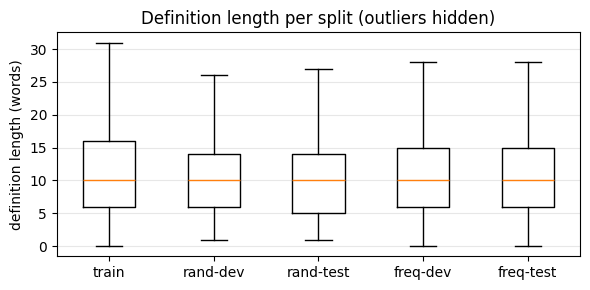

In [7]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.boxplot([df.loc[df["set"] == s, "n_words"] for s in SPLITS], showfliers=False)
ax.set_xticks(range(1, len(SPLITS) + 1), SPLITS)
ax.set_ylabel("definition length (words)")
ax.set_title("Definition length per split (outliers hidden)")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/definition_length.png", dpi=200)
plt.show()

## 4. Lemma overlap with the training set

In [8]:
# Share of senses whose lemma also has senses in train: tells whether a model can memorise lemmas.
train_lemmas = set(df.loc[df["set"] == "train", "lemma"])
df[df["set"] != "train"].groupby("set")["lemma"].apply(lambda s: s.isin(train_lemmas).mean())

,lemma
set,
freq-dev,0.0
freq-test,0.0
rand-dev,0.0
rand-test,0.0


## 5. Shortest definitions (likely hard cases)

In [9]:
df[df["definition"] != ""].nsmallest(10, "n_words")[["lemma", "definition", "supersense", "set"]]

,lemma,definition,supersense,set
95,Vtesse,Vicomtesse.,person,rand-test
177,montant,Piquant.,attribute,rand-dev
193,gynéco,Gynécologue.,person,rand-dev
194,posture,Statue.,artifact,rand-dev
229,enchanterie,Enchantement.,other,rand-test
250,chadèque,Pamplemousse.,food,rand-dev
258,assistance_en_ligne,Téléassistance.,person,rand-dev
341,rapiat,Radin.,person,rand-test
429,skeud,Disque.,artifact*cognition,rand-test
456,nalǘn,Année.,time,rand-dev


## 6. What this means for the experiments

- The splits come from two different samplings. `rand-*` are random Wiktionary senses: 26–33 % are `person` (about 18 % of all `rand-*` senses are demonyms, *Habitant de …*). `freq-*` are senses of frequent lemmas (84–88 % of them appear in FrSemCor, vs 14–27 % in `rand-*`) and are dominated by `act`, `artifact`, `cognition` and `other`. `train` is in between.
- We therefore use macro-F1 as the main metric, and discuss results on `freq-test` and `rand-test` separately, because a configuration tuned on `rand-dev` may not transfer to `freq-test`.
- `rand-dev` has no `relation` instance and only 1–4 instances of several classes, so per-class scores on `rand-dev` are noisy; we compare configurations on macro-F1 and on accuracy.
- Definitions are short (median 10 words). 19 senses have an empty definition; for them only the lemma can help, which is one argument for giving the lemma.
- No dev or test lemma occurs in `train` (the splits are made by lemma): a fine-tuned model cannot memorise lemmas, and ICL demonstrations never contain the query word.
- The lemma is rarely copied in its own definition (4–12 %), so giving it adds information.